# E0. Thiết lập đánh giá

Trước khi so sánh model hay cách tiền xử lý, nhóm cần thống nhất đo bằng độ đo nào và đo theo quy trình nào
(Bài 05, Đánh giá mô hình). Phần này xét ba vấn đề:

1. Độ đo: vì sao dùng ROC AUC thay vì accuracy hay F1.
2. Quy trình đánh giá: vì sao dùng K-fold CV với 5 fold cố định trong `data/folds.csv`, thay vì chấm trên tập train
   hay tách train/test một lần.
3. Rò rỉ dữ liệu (data leakage): thế nào là dự đoán out-of-fold (OOF) "sạch", và OOF "bẩn" làm điểm CV lệch bao
   nhiêu.

Các model ở đây (Logistic Regression, Decision Tree, LightGBM cấu hình đơn giản) chỉ dùng để minh hoạ; phần so
sánh model nằm ở E3.

> **Trong cuộc thi.** `data/folds.csv` được tạo ngày 12/10 (`src/make_folds.py`) và dùng cho mọi model, mọi bản
> stacking. Quy tắc OOF sạch được áp dụng từ model đầu tiên (`A_lgb`, 14/10): early stopping dùng 10% tách từ phần
> train của fold, target encoding tính trong fold. Khi chuyển sang stacking, nhóm siết dần ngưỡng giữ một thay
> đổi. Ngày 18/10 ngưỡng là tăng 3×10⁻⁵ và ổn định qua 3 meta seed; từ 20/10 là tăng ở cả 3 seed, ít nhất 10/15
> fold và ít nhất 5×10⁻⁶ (gọi tắt là "cổng"). Các mục dưới đây đo lại bằng thí nghiệm lý do của từng quy tắc.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from config import CAT_COLS, FEATURES, NUM_COLS, RESULTS_DIR, SCORE_COLS, TARGET
from cv import log_result, run_cv
from data import load_data
import plot as P

pd.set_option("display.width", 200)
train, test = load_data()
y = train[TARGET].values
DEP, ARR = "Departure Delay in Minutes", "Arrival Delay in Minutes"
N_JOBS = 6  # giới hạn số luồng để máy không quá tải

## 1. Độ đo
### 1.1 Mô hình baseline
Logistic Regression với tiền xử lý tối thiểu. `Arrival Delay` thiếu được điền bằng `Departure Delay`, hai cột delay
lấy log1p, cột số và cột điểm chuẩn hoá z-score, cột category mã hoá one-hot. Toàn bộ pipeline đặt trong
`fit_predict`, vì vậy chỉ học từ phần train của mỗi fold.

In [2]:
def basic_frame(X):
    X = X.copy()
    X[ARR] = X[ARR].fillna(X[DEP])
    X[DEP], X[ARR] = np.log1p(X[DEP]), np.log1p(X[ARR])
    return X


def lr_pipeline(C=1.0):
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS + SCORE_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])
    return make_pipeline(FunctionTransformer(basic_frame), pre, LogisticRegression(C=C, max_iter=500))


def fp_lr(X_tr, y_tr, X_va, X_te):
    m = lr_pipeline().fit(X_tr, y_tr)
    return m.predict_proba(X_va)[:, 1], m.predict_proba(X_te)[:, 1]


base = run_cv(fp_lr, train, test, FEATURES, name="E0_lr_baseline")
log_result("E0_setup", "lr_baseline", base, notes="LR + one-hot + z-score + log1p delay; baseline cho E2/E3")
oof = base["oof"]

  fold 0: AUC 0.922563 (5s)


  fold 1: AUC 0.921549 (11s)


  fold 2: AUC 0.921539 (16s)


  fold 3: AUC 0.921460 (22s)


  fold 4: AUC 0.921509 (27s)


CV AUC 0.921725 | fold mean 0.921724 ± 0.000421


Đã lưu oof_E0_lr_baseline.npy, test_E0_lr_baseline.npy | CV AUC = 0.921725


### 1.2 AUC chỉ phụ thuộc thứ tự
Nếu biến đổi xác suất dự đoán bằng một hàm đồng biến (luỹ thừa, thứ hạng, kéo giãn logit) thì AUC giữ nguyên, còn
accuracy, F1 ở ngưỡng 0,5 và log loss đều thay đổi. Cuộc thi chấm bằng AUC, nên model chỉ cần xếp hạng hành khách
đúng thứ tự; không cần chọn ngưỡng hay hiệu chỉnh xác suất.

In [3]:
logit = np.log(oof / (1 - oof))
variants = {
    "p (gốc)": oof,
    "p³": oof ** 3,
    "rank(p) / n": rankdata(oof) / len(oof),
    "sigmoid(2·logit p)": 1 / (1 + np.exp(-2 * logit)),
}
inv = pd.DataFrame({
    name: {"AUC": roc_auc_score(y, p), "accuracy @0,5": accuracy_score(y, p > 0.5),
           "F1 @0,5": f1_score(y, p > 0.5), "log loss": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7))}
    for name, p in variants.items()
}).T
inv.to_csv(RESULTS_DIR / "E0_metric_invariance.csv")
inv.round(5)

,AUC,"accuracy @0,5","F1 @0,5",log loss
p (gốc),0.92172,0.87841,0.86082,0.34390
p³,0.92172,0.84604,0.80066,0.61320
rank(p) / n,0.92172,0.85293,0.84414,0.41666
sigmoid(2·logit p),0.92172,0.87841,0.86082,0.43385


### 1.3 Accuracy / F1 phụ thuộc ngưỡng, AUC thì không
Nhãn khá cân bằng (44% hài lòng) nên accuracy không quá lệch, nhưng vẫn phải chọn một ngưỡng. Đường ROC và AUC
xét mọi ngưỡng cùng lúc.

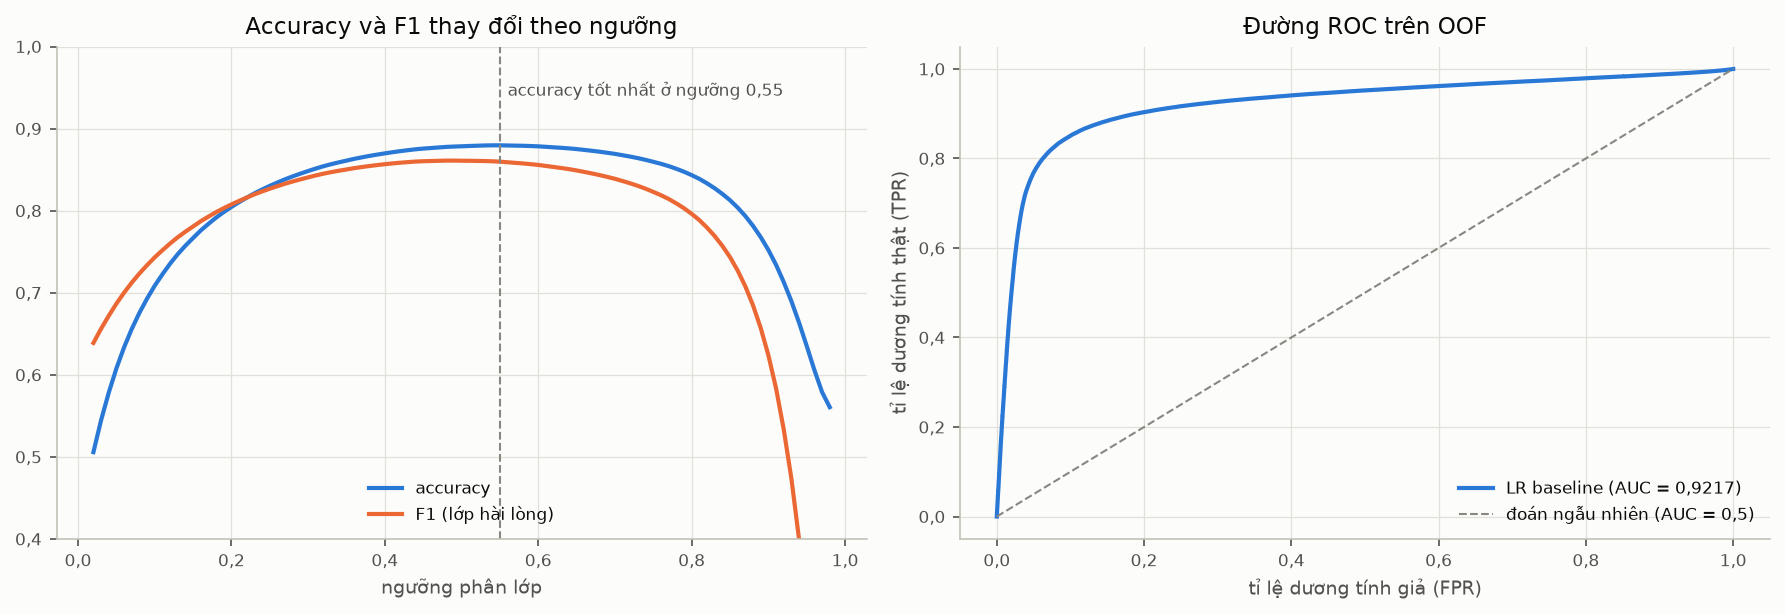

In [4]:
th = np.linspace(0.02, 0.98, 97)
acc = [accuracy_score(y, oof > t) for t in th]
f1 = [f1_score(y, oof > t) for t in th]
fpr, tpr, _ = roc_curve(y, oof)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(th, acc, color=P.BLUE, label="accuracy")
axes[0].plot(th, f1, color=P.ORANGE, label="F1 (lớp hài lòng)")
best = th[int(np.argmax(acc))]
axes[0].axvline(best, color=P.REF, ls="--", lw=1)
axes[0].text(best + 0.01, 0.94, f"accuracy tốt nhất ở ngưỡng {best:.2f}", fontsize=8, color=P.INK_2)
axes[0].set_xlabel("ngưỡng phân lớp")
axes[0].set_ylim(0.4, 1)
axes[0].set_title("Accuracy và F1 thay đổi theo ngưỡng")
axes[0].legend(loc="lower center")
axes[1].plot(fpr, tpr, color=P.BLUE, label=f"LR baseline (AUC = {base['cv_auc']:.4f})")
axes[1].plot([0, 1], [0, 1], color=P.REF, ls="--", lw=1, label="đoán ngẫu nhiên (AUC = 0,5)")
axes[1].set_xlabel("tỉ lệ dương tính giả (FPR)")
axes[1].set_ylabel("tỉ lệ dương tính thật (TPR)")
axes[1].set_title("Đường ROC trên OOF")
axes[1].legend(loc="lower right")
fig.tight_layout()
P.save(fig, "E0_01_threshold_roc")

**Nhận xét mục 1**
- LR baseline đạt CV AUC 0,92172, các fold nằm trong khoảng 0,9215–0,9226 (độ lệch chuẩn 0,0004). Đây là mốc so
  sánh cho E2 và E3.
- Bốn phép biến đổi đồng biến cho AUC giống hệt nhau (0,92172). Trong khi đó accuracy ở ngưỡng 0,5 giảm từ 0,878
  xuống 0,846, F1 giảm từ 0,861 xuống 0,801 và log loss tăng từ 0,344 lên 0,613. Như vậy AUC chỉ phụ thuộc vào thứ
  tự xếp hạng.
- Accuracy cao nhất khoảng 0,88 ở ngưỡng 0,55, còn F1 đạt cao nhất ở một ngưỡng khác. Dùng accuracy hay F1 thì phải
  chọn thêm ngưỡng, và ngưỡng chọn trên dữ liệu đánh giá cũng có thể bị overfit.
- Quyết định: đánh giá bằng AUC trên OOF, đúng độ đo của cuộc thi; nộp xác suất, không chỉnh ngưỡng. Khi kết hợp
  nhiều model, có thể trộn theo thứ hạng hoặc logit mà không ảnh hưởng tới độ đo (E5).

## 2. Ba quy trình đánh giá (Bài 05)
### 2.1 Quy trình 1: đánh giá ngay trên tập train
So sánh AUC trên chính dữ liệu đã dùng để học với AUC 5-fold CV, cho ba model: LR, cây quyết định độ sâu 10 và cây
không giới hạn độ sâu.

In [5]:
def tree_frame(X):
    X = basic_frame(X)
    for c in CAT_COLS:
        X[c] = X[c].astype("category").cat.codes
    return X


def fp_tree(depth):
    def fp(X_tr, y_tr, X_va, X_te):
        m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(tree_frame(X_tr), y_tr)
        return m.predict_proba(tree_frame(X_va))[:, 1], m.predict_proba(tree_frame(X_te))[:, 1]
    return fp


rows = []
for name, fp in [("Logistic Regression", fp_lr), ("Decision Tree (depth 10)", fp_tree(10)),
                 ("Decision Tree (không giới hạn)", fp_tree(None))]:
    p_tr, _ = fp(train[FEATURES], y, train[FEATURES], test[FEATURES].head(5))
    res = base if name == "Logistic Regression" else run_cv(fp, train, test, FEATURES, verbose=False)
    rows.append({"mô hình": name, "AUC trên train (QT1)": roc_auc_score(y, p_tr), "AUC 5-fold CV (QT3)": res["cv_auc"]})
qt1 = pd.DataFrame(rows).set_index("mô hình")
qt1["chênh lệch"] = qt1.iloc[:, 0] - qt1.iloc[:, 1]
qt1.to_csv(RESULTS_DIR / "E0_resubstitution.csv")
qt1.round(4)

,AUC trên train (QT1),AUC 5-fold CV (QT3),chênh lệch
mô hình,,,
Logistic Regression,0.9217,0.9217,0.0000
Decision Tree (depth 10),0.9543,0.9513,0.0031
Decision Tree (không giới hạn),1.0000,0.8641,0.1359


### 2.2 Quy trình 2 (một lần tách train/test) và quy trình 3 (K-fold)
Tách ngẫu nhiên 80/20 mười lần với 10 seed khác nhau (quy trình 2), so với 5 fold cố định (quy trình 3). Ngoài độ
ổn định, K-fold còn cho mỗi dòng train đúng một dự đoán OOF, là đầu vào cho ensemble ở E5.

*Các lần tách ngẫu nhiên ở đây chỉ để đo độ dao động của quy trình; mọi so sánh model trong đồ án đều dùng
`folds.csv`.*

In [6]:
hold = []
for seed in range(10):
    tr_i, va_i = train_test_split(np.arange(len(train)), test_size=0.2, stratify=y, random_state=seed)
    m = lr_pipeline().fit(train.loc[tr_i, FEATURES], y[tr_i])
    hold.append(roc_auc_score(y[va_i], m.predict_proba(train.loc[va_i, FEATURES])[:, 1]))
hold = np.array(hold)
fold_auc = np.array(base["fold_auc"])
proc = pd.DataFrame({
    "QT2: holdout 80/20 (10 seed)": {"trung bình": hold.mean(), "độ lệch chuẩn": hold.std(), "min": hold.min(), "max": hold.max()},
    "QT3: từng fold (5 fold)": {"trung bình": fold_auc.mean(), "độ lệch chuẩn": fold_auc.std(), "min": fold_auc.min(), "max": fold_auc.max()},
}).T
proc["max - min"] = proc["max"] - proc["min"]
proc.to_csv(RESULTS_DIR / "E0_holdout_vs_kfold.csv")
print(f"Ước lượng độ lệch chuẩn của trung bình 5 fold ≈ {fold_auc.std(ddof=1) / np.sqrt(5):.6f}")
proc.round(6)

Ước lượng độ lệch chuẩn của trung bình 5 fold ≈ 0.000210


,trung bình,độ lệch chuẩn,min,max,max - min
QT2: holdout 80/20 (10 seed),0.921473,0.000681,0.920264,0.922495,0.002232
QT3: từng fold (5 fold),0.921724,0.000421,0.921460,0.922563,0.001104


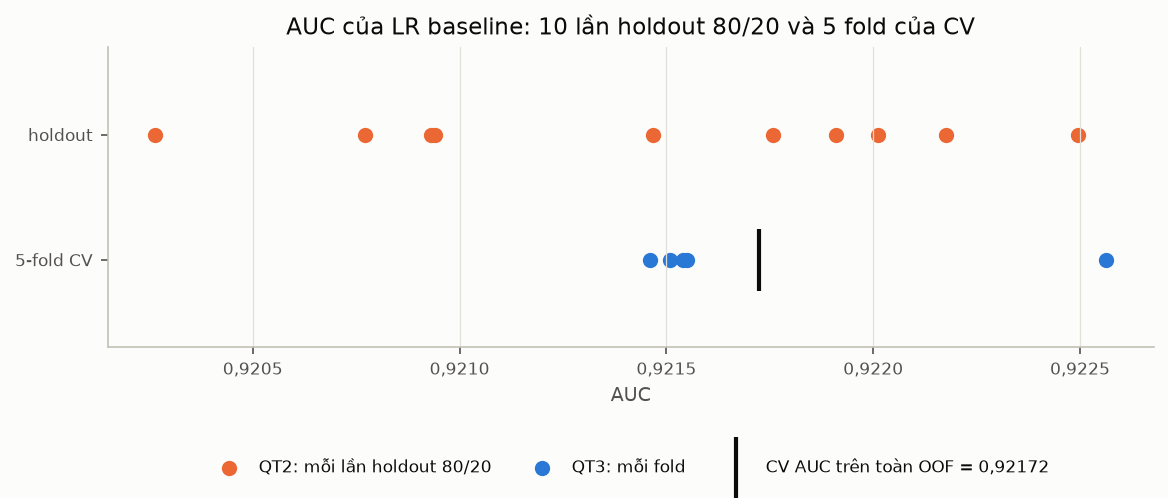

In [7]:
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.scatter(hold, np.full_like(hold, 1), color=P.ORANGE, s=40, label="QT2: mỗi lần holdout 80/20")
ax.scatter(fold_auc, np.full_like(fold_auc, 0), color=P.BLUE, s=40, label="QT3: mỗi fold")
ax.scatter([base["cv_auc"]], [0], marker="|", s=900, color=P.INK, label=f"CV AUC trên toàn OOF = {base['cv_auc']:.5f}")
ax.set_yticks([0, 1], ["5-fold CV", "holdout"])
ax.set_ylim(-0.7, 1.7)
ax.set_xlabel("AUC")
ax.set_title("AUC của LR baseline: 10 lần holdout 80/20 và 5 fold của CV")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3)
ax.grid(axis="y", visible=False)
P.save(fig, "E0_02_holdout_vs_kfold")

**Nhận xét mục 2**
- Chấm trên tập train (quy trình 1) sai lệch nặng với model phức tạp. Với LR, AUC trên train bằng CV (0,9217) vì
  model đơn giản, bias cao và không overfit. Cây độ sâu 10 chênh 0,003. Cây không giới hạn đạt 1,0000 trên train
  nhưng chỉ 0,8641 trên CV, chênh 0,136, tức là cây đã học thuộc dữ liệu train (overfitting, Bài 07).
- Một lần holdout dao động nhiều. Mười lần tách 80/20 cho AUC từ 0,9203 đến 0,9225 (biên độ 0,0022, độ lệch chuẩn
  0,0007). Độ lệch chuẩn ước lượng của trung bình 5 fold khoảng 0,0002, nhỏ hơn khoảng 3 lần. Nếu chỉ dùng một lần
  holdout, hai model chênh nhau 0,0005 vẫn có thể đảo thứ tự chỉ vì cách chia.
- So sánh hai model theo cặp trên cùng 5 fold còn ổn định hơn so sánh hai giá trị trung bình, do phần chênh lệch về
  độ khó giữa các fold bị loại bỏ. Vì vậy các bảng kết quả trong đồ án đều kèm chênh lệch từng fold và số fold tăng.
- K-fold cho dự đoán OOF trên toàn bộ 700 nghìn dòng train; đây là đầu vào cho stacking ở E5.

## 3. OOF sạch và OOF bẩn: rò rỉ dữ liệu làm CV "đẹp giả"
Muốn biết CV lệch bao nhiêu thì cần một tập chưa từng được dùng. Nhóm lấy fold 0–3 làm tập phát triển (dev, chạy CV
4 fold như bình thường) và giữ fold 4 làm tập test giả. Với model sạch, CV trên dev xấp xỉ điểm trên fold 4; với
model bẩn, CV cao hơn điểm thật.

Model là LightGBM (cột category để kiểu `category`). Xét hai kiểu rò rỉ thường gặp:
- (a) Target encoding tính ngoài fold. Cột "hồ sơ 13 điểm dịch vụ" (rất nhiều giá trị khác nhau) được mã hoá bằng tỉ
  lệ hài lòng trung bình của hồ sơ đó. Bản bẩn tính tỉ lệ một lần trên toàn bộ dev, gồm cả nhãn của fold đang chấm
  và nhãn của chính dòng đó. Bản sạch tính trong từng fold; dòng train dùng giá trị out-of-fold của các fold con.
- (b) Early stopping trên fold đang chấm. Bản bẩn dừng sớm theo chính fold validation, tức chọn số cây tốt nhất cho
  fold đó. Bản sạch tách 10% từ phần train của fold để dừng sớm.

In [8]:
dev_mask = train["fold"].values != 4
dev = train[dev_mask].reset_index(drop=True)
hold4 = train[~dev_mask].reset_index(drop=True)
y_dev, y_hold = dev[TARGET].values, hold4[TARGET].values
profile = lambda df: pd.util.hash_pandas_object(df[SCORE_COLS], index=False).values  # noqa: E731
print(f"dev {len(dev)} dòng (fold 0-3), test giả {len(hold4)} dòng (fold 4)")
print(f"Số hồ sơ 13 điểm khác nhau trong dev: {len(np.unique(profile(dev))):,}")


def te_map(keys, target, m=20):
    """Tỉ lệ hài lòng theo khoá, làm trơn về tỉ lệ chung với trọng số m."""
    g = pd.DataFrame({"k": keys, "y": target}).groupby("k")["y"].agg(["sum", "count"])
    prior = target.mean()
    return ((g["sum"] + m * prior) / (g["count"] + m)), prior


def te_apply(keys, mapping, prior):
    return pd.Series(keys).map(mapping).fillna(prior).values


def te_oof(keys, target, n_splits=5):
    """TE cho chính các dòng train: mỗi dòng lấy giá trị tính từ các dòng khác fold (lồng trong)."""
    out = np.zeros(len(keys))
    for a, b in KFold(n_splits, shuffle=True, random_state=42).split(keys):
        mp, pr = te_map(keys[a], target[a])
        out[b] = te_apply(keys[b], mp, pr)
    return out


def lgb_frame(df, te=None):
    X = df[FEATURES].copy()
    for c in CAT_COLS:
        X[c] = X[c].astype("category")
    if te is not None:
        X["te_profile"] = te
    return X


LGB = dict(learning_rate=0.1, num_leaves=63, min_child_samples=50, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.8, n_jobs=N_JOBS, verbose=-1, random_state=42)


def dev_cv_and_holdout(make_sets, n_estimators=300):
    """CV 4 fold trên dev + điểm trên fold 4 (trung bình dự đoán của 4 model fold, như khi nộp bài)."""
    fold_dev = dev["fold"].values
    oof_dev = np.zeros(len(dev))
    p_hold = np.zeros(len(hold4))
    for k in range(4):
        tr, va = fold_dev != k, fold_dev == k
        X_tr, X_va, X_ho = make_sets(tr, va)
        m = lgb.LGBMClassifier(n_estimators=n_estimators, **LGB).fit(X_tr, y_dev[tr])
        oof_dev[va] = m.predict_proba(X_va)[:, 1]
        p_hold += m.predict_proba(X_ho)[:, 1] / 4
    return roc_auc_score(y_dev, oof_dev), roc_auc_score(y_hold, p_hold)


keys_dev, keys_hold = profile(dev), profile(hold4)
mp_all, pr_all = te_map(keys_dev, y_dev)
te_leak_dev = te_apply(keys_dev, mp_all, pr_all)  # bẩn: dùng cả nhãn fold đang chấm + nhãn chính dòng đó


def sets_none(tr, va):
    return lgb_frame(dev[tr]), lgb_frame(dev[va]), lgb_frame(hold4)


def sets_leak(tr, va):
    return (lgb_frame(dev[tr], te_leak_dev[tr]), lgb_frame(dev[va], te_leak_dev[va]),
            lgb_frame(hold4, te_apply(keys_hold, mp_all, pr_all)))


def sets_clean(tr, va):
    mp, pr = te_map(keys_dev[tr], y_dev[tr])
    return (lgb_frame(dev[tr], te_oof(keys_dev[tr], y_dev[tr])), lgb_frame(dev[va], te_apply(keys_dev[va], mp, pr)),
            lgb_frame(hold4, te_apply(keys_hold, mp, pr)))


leak_rows = []
for name, fn in [("không TE (21 cột gốc)", sets_none), ("TE bẩn (tính trên toàn dev)", sets_leak),
                 ("TE sạch (tính trong fold)", sets_clean)]:
    t0 = time.time()
    cv_auc, hold_auc = dev_cv_and_holdout(fn)
    leak_rows.append({"kiểu": "(a) target encoding", "biến thể": name, "CV trên dev": cv_auc, "AUC fold 4 (thật)": hold_auc})
    print(f"{name}: CV {cv_auc:.5f} | fold 4 {hold_auc:.5f} ({time.time() - t0:.0f}s)")

dev 559708 dòng (fold 0-3), test giả 139927 dòng (fold 4)


Số hồ sơ 13 điểm khác nhau trong dev: 285,650


không TE (21 cột gốc): CV 0.95810 | fold 4 0.95899 (54s)


TE bẩn (tính trên toàn dev): CV 0.99345 | fold 4 0.90817 (53s)


TE sạch (tính trong fold): CV 0.95778 | fold 4 0.95881 (56s)


In [9]:
def es_cv_and_holdout(clean):
    fold_dev = dev["fold"].values
    oof_dev, p_hold, iters = np.zeros(len(dev)), np.zeros(len(hold4)), []
    for k in range(4):
        tr_idx, va_idx = np.where(fold_dev != k)[0], np.where(fold_dev == k)[0]
        if clean:
            fit_idx, es_idx = train_test_split(tr_idx, test_size=0.1, stratify=y_dev[tr_idx], random_state=42)
        else:
            fit_idx, es_idx = tr_idx, va_idx
        m = lgb.LGBMClassifier(n_estimators=3000, **LGB).fit(
            lgb_frame(dev.iloc[fit_idx]), y_dev[fit_idx],
            eval_set=[(lgb_frame(dev.iloc[es_idx]), y_dev[es_idx])], eval_metric="auc",
            callbacks=[lgb.early_stopping(100, verbose=False)])
        iters.append(m.best_iteration_)
        oof_dev[va_idx] = m.predict_proba(lgb_frame(dev.iloc[va_idx]))[:, 1]
        p_hold += m.predict_proba(lgb_frame(hold4))[:, 1] / 4
    return roc_auc_score(y_dev, oof_dev), roc_auc_score(y_hold, p_hold), iters


for name, clean in [("ES bẩn (dừng theo fold đang chấm)", False), ("ES sạch (tách 10% từ phần train)", True)]:
    t0 = time.time()
    cv_auc, hold_auc, iters = es_cv_and_holdout(clean)
    leak_rows.append({"kiểu": "(b) early stopping", "biến thể": name, "CV trên dev": cv_auc, "AUC fold 4 (thật)": hold_auc})
    print(f"{name}: CV {cv_auc:.5f} | fold 4 {hold_auc:.5f} | số cây {iters} ({time.time() - t0:.0f}s)")

leak = pd.DataFrame(leak_rows)
leak["CV − thật"] = leak["CV trên dev"] - leak["AUC fold 4 (thật)"]
leak.to_csv(RESULTS_DIR / "E0_leakage.csv", index=False)
leak.round(5)

ES bẩn (dừng theo fold đang chấm): CV 0.95831 | fold 4 0.95903 | số cây [109, 112, 148, 198] (58s)


ES sạch (tách 10% từ phần train): CV 0.95812 | fold 4 0.95905 | số cây [157, 173, 117, 154] (48s)


,kiểu,biến thể,CV trên dev,AUC fold 4 (thật),CV − thật
0,(a) target encoding,không TE (21 cột gốc),0.95810,0.95899,-0.00088
1,(a) target encoding,TE bẩn (tính trên toàn dev),0.99345,0.90817,0.08528
2,(a) target encoding,TE sạch (tính trong fold),0.95778,0.95881,-0.00102
3,(b) early stopping,ES bẩn (dừng theo fold đang chấm),0.95831,0.95903,-0.00072
4,(b) early stopping,ES sạch (tách 10% từ phần train),0.95812,0.95905,-0.00093


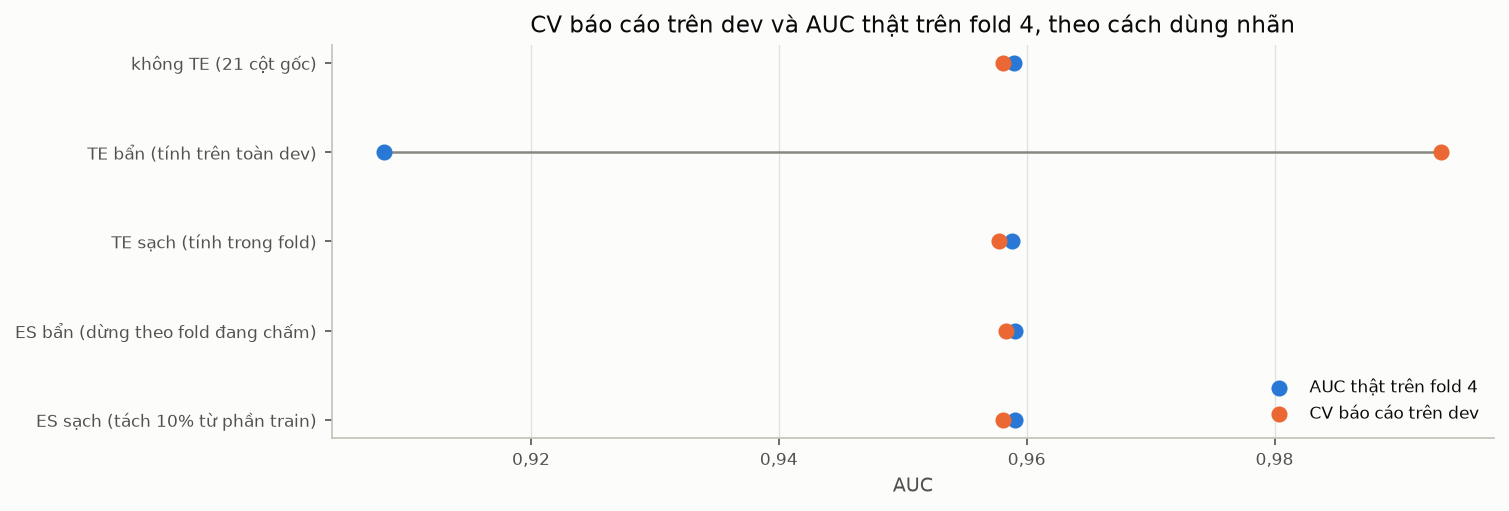

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.4))
yy = np.arange(len(leak))[::-1]
ax.scatter(leak["AUC fold 4 (thật)"], yy, color=P.BLUE, s=45, zorder=3, label="AUC thật trên fold 4")
ax.scatter(leak["CV trên dev"], yy, color=P.ORANGE, s=45, zorder=3, label="CV báo cáo trên dev")
for yi, a, b in zip(yy, leak["AUC fold 4 (thật)"], leak["CV trên dev"]):
    ax.plot([a, b], [yi, yi], color=P.INK_3, lw=1.2, zorder=2)
ax.set_yticks(yy, leak["biến thể"])
ax.set_xlabel("AUC")
ax.set_title("CV báo cáo trên dev và AUC thật trên fold 4, theo cách dùng nhãn")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
P.save(fig, "E0_03_leakage")

**Nhận xét mục 3**
- Target encoding (TE) bẩn cho **CV 0,9935 nhưng điểm thật chỉ 0,9082**. CV báo cao hơn 0,085, và điểm thật còn thấp
  hơn model không dùng TE (0,9590). Tập dev có 285.650 hồ sơ điểm khác nhau trên 560 nghìn dòng, phần lớn hồ sơ chỉ
  có 1–2 dòng. Vì vậy khi tính cả nhãn của chính dòng đó, giá trị TE gần như là nhãn, và model học cách đọc lại nhãn
  thay vì học quy luật.
- TE sạch cho CV 0,9578 và điểm thật 0,9588, ngang với không dùng TE. Feature này thực chất không giúp gì; chỉ khi
  tính sai cách nó mới trông như một cải thiện lớn.
- Early stopping bẩn làm CV tăng 2×10⁻⁴ (0,95831 so với 0,95812) nhưng điểm thật trên fold 4 không đổi (0,95903 so
  với 0,95905). Mức lệch này nhỏ, nhưng cùng cỡ với chênh lệch giữa các phương án ở giai đoạn stacking (10⁻⁶ đến
  10⁻⁴), nên đủ để chọn sai phương án.
- Ở mọi biến thể sạch, AUC trên fold 4 cao hơn CV khoảng 0,001, nghĩa là fold 4 dễ hơn mức trung bình. Do đó nên so
  các biến thể với nhau trên cùng fold, không so CV với một con số đơn lẻ.

## 4. Quy ước đánh giá cho toàn bộ đồ án
1. Một bộ fold duy nhất `data/folds.csv` (StratifiedKFold 5 fold, seed 42) cho mọi thí nghiệm và mọi model.
2. Độ đo: AUC trên dự đoán OOF. Mỗi kết quả báo cáo CV AUC trên toàn bộ OOF, trung bình ± độ lệch chuẩn 5 fold,
   chênh lệch so với baseline và số fold tăng (`src/cv.py`).
3. Mọi bước học từ dữ liệu (điền thiếu, chuẩn hoá, target encoding, chọn feature, gom cụm, PCA) chỉ fit trên phần
   train của fold; `run_cv` bắt buộc điều này qua hàm `fit_predict`.
4. Early stopping dùng 10% tách từ phần train của fold, hoặc cố định số vòng lặp.
5. Chỉ giữ một thay đổi khi nó tăng ở phần lớn fold (với thay đổi nhỏ thì phải tăng qua nhiều seed). Chênh lệch nhỏ
   hơn độ dao động giữa các cách chia được coi là bằng nhau.
6. Public leaderboard (60 nghìn dòng) chỉ để tham khảo; đối chiếu CV, public và private ở E6.